In [176]:
# 1. LIBRERÍAS
import numpy as np
import os # sirve para interactuar con el sistema de archivos y directorios del sistema operativo
from PIL import Image # con esto importamos la librería de imágenes que sirve para abrir, manipular y guardar imágenes en diferentes formatos
import matplotlib.pyplot as plt

In [177]:
# 2. FUNCIÓN (AUTOMÁTICA POR CARPETAS)
# Esta función recorre las carpetas de un directorio, carga las imágenes, las redimensiona y normaliza, 
# y asigna etiquetas basadas en el nombre de la carpeta.
def cargar_dataset(base_dir, img_size=(150,150)):
    imagenes = []
    etiquetas = []

    for clase in os.listdir(base_dir):
        ruta_clase = os.path.join(base_dir, clase)

        if os.path.isdir(ruta_clase):
            for archivo in os.listdir(ruta_clase):
                if archivo.lower().endswith(('.jpg','.jpeg','.png')): # Verifica que el archivo sea una imagen para evitar errores  

                    ruta = os.path.join(ruta_clase, archivo)

                    img = Image.open(ruta) # Carga la imagen
                    img = img.resize(img_size) # Redimensiona la imagen al tamaño especificado
                    img = np.array(img) / 255.0 #  Normaliza los valores de píxeles a [0,1], 250 es debido a que los valores de píxeles van de 0 a 255, y al dividirlo por 255.0 se obtiene un rango de 0 a 1

                    imagenes.append(img)
                    etiquetas.append(clase)

    return np.array(imagenes), np.array(etiquetas) # finalmente guarda todas las imagenes en una lista y todas las etiquetas en otra

In [178]:
# 3. Lectura de la ruta
base_dir = r"Cars_Body_Type/train"

## Fuente del dataset

Para este ejercicio se utiliza el dataset **Cars Body Type Cropped**, publicado en Kaggle por **ademboukhris**.

[Consultar el dataset en Kaggle](https://www.kaggle.com/datasets/ademboukhris/cars-body-type-cropped?resource=download-directory)

En este notebook se cargaron **5350 imágenes** distribuidas en **7 clases**, correspondientes a diferentes tipos de carrocería:

- Convertible
- Coupe
- Hatchback
- Pick-Up
- SUV
- Sedan
- VAN

In [179]:
# 4. CARGAR DATOS
X, Y = cargar_dataset(base_dir)

print("Shape:", X.shape)
print("Ejemplo etiquetas:", Y[:10])

# Nos arroja que son 5350 imagenes, 150x 150 pixeles, y 3 canales (RGB) por ser imagenes a color

Shape: (5350, 150, 150, 3)
Ejemplo etiquetas: ['Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible'
 'Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible']


In [180]:
# Conteo de imágenes cargadas por clase
clases, conteos = np.unique(Y, return_counts=True)
for clase, conteo in zip(clases, conteos):
    print(f"{clase}: {conteo} imágenes")

print("Cumple mínimo de 200 por clase:", bool(np.all(conteos >= 200)))

Convertible: 811 imágenes
Coupe: 721 imágenes
Hatchback: 701 imágenes
Pick-Up: 759 imágenes
SUV: 847 imágenes
Sedan: 729 imágenes
VAN: 782 imágenes
Cumple mínimo de 200 por clase: True


In [181]:
# 5. CODIFICAR ETIQUETAS
# En este proceso se utiliza LabelEncoder para convertir las etiquetas de texto en números enteros, 
# lo que es necesario para el entrenamiento del modelo. Es decir, cada categoría queda con un número asignado
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

print("Clases:", labelencoder.classes_)

Clases: ['Convertible' 'Coupe' 'Hatchback' 'Pick-Up' 'SUV' 'Sedan' 'VAN']


In [182]:
# 6. SPLIT
# Aquí se divide el conjunto de datos en entrenamiento y prueba utilizando train_test_split de sklearn,
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [183]:
# Separación de entrenamiento y validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

## Preparación de las imágenes

Para entrenar el modelo, se prepararon las imágenes mediante los siguientes pasos:

- **Carga y asignación de etiquetas:** se recorren las subcarpetas de `train` y se utiliza el nombre de cada carpeta como etiqueta. Esto permite relacionar cada imagen con su tipo de carrocería sin etiquetarla manualmente.

- **Redimensionado a 150 × 150 píxeles:** todas las imágenes se llevan al mismo tamaño para que tengan dimensiones compatibles con la entrada de la red. Este tamaño busca un equilibrio entre el detalle visual y el costo de procesamiento.

- **Normalización:** se dividen los valores de los píxeles entre 255 para pasarlos del rango de 0 a 255 al rango de 0 a 1. Esto mantiene una escala de entrada uniforme y puede facilitar la optimización durante el entrenamiento.

- **Codificación de etiquetas:** se utiliza `LabelEncoder` para convertir los nombres de las clases en etiquetas numéricas que puedan utilizarse al entrenar el modelo.

- **Separación de datos:** se reserva el 80 % de las imágenes para entrenamiento y el 20 % para evaluación. Se utiliza una división estratificada para mantener aproximadamente la proporción de cada clase en ambos conjuntos.

## MODELO BASE

In [184]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout, RandomFlip, RandomRotation, RandomZoom, GlobalAveragePooling2D
import tensorflow as tf

tf.random.set_seed(3)
np.random.seed(3)

modelo = Sequential()

# Primera capa convolucional para extraer características básicas.
modelo.add(Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)))
modelo.add(MaxPooling2D(2,2))

# Convierte los mapas de características en un vector.
modelo.add(Flatten())

# Desactiva aleatoriamente algunas conexiones durante el entrenamiento.
modelo.add(Dropout(0.2))

# Capa densa para realizar la clasificación.
modelo.add(Dense(32, activation='relu'))

# Clasificación en las siete categorías.
modelo.add(Dense(7, activation='softmax'))

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = modelo.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=8
)

/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20


I0000 00:00:1793643840.585850   39667 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_921499__.22


428/428 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.1370 - loss: 2.0740
Epoch 2/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1735 - loss: 1.9355
Epoch 3/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.2760 - loss: 1.8130
Epoch 4/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.3180 - loss: 1.6900
Epoch 5/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.3765 - loss: 1.4673
Epoch 6/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5505 - loss: 1.1004
Epoch 7/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6694 - loss: 0.8019
Epoch 8/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7526 - loss: 0.5820
Epoch 9/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8140 - loss: 0.4611
Epoch 10/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8513 - loss: 0.3657
Epoch 11/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8855 - loss: 0.2872
Epoch 12/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy

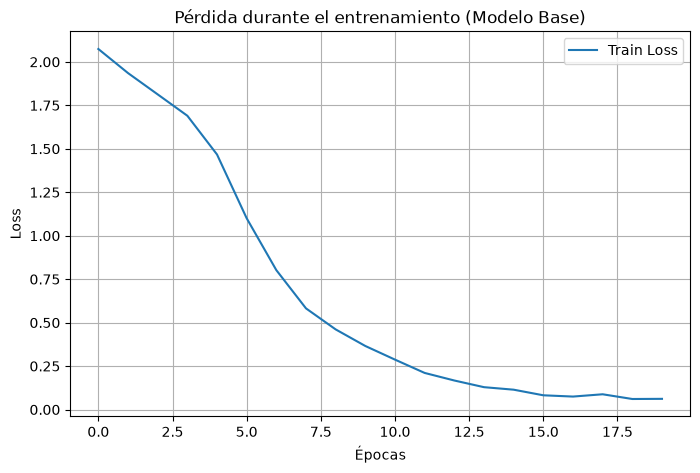

In [185]:
# Gráfica de la pérdida durante el entrenamiento del modelo base.
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

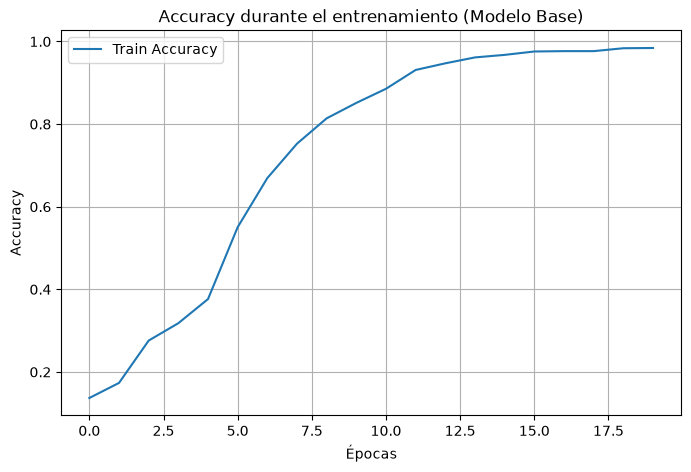

In [186]:
# Gráfica del accuracy durante el entrenamiento del modelo base.
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [187]:
# Métricas de evaluación para el modelo base utilizando accuracy_score y f1_score de sklearn.
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
===== TRAIN =====
Accuracy: 0.9856892523364486
F1-score: 0.985650724035606

===== TEST =====
Accuracy: 0.5719626168224299
F1-score: 0.579616746070627


## Interpretación de los resultados del modelo base

Después de entrenar durante 20 épocas, se obtuvieron los siguientes resultados en la evaluación:

| Conjunto | Accuracy | F1-score ponderado |
| --- | ---: | ---: |
| Entrenamiento | 0.82477 | 0.82180 |
| Prueba | 0.73551 | 0.73192 |

### Conclusión

El modelo clasifica correctamente aproximadamente el 73.55 % de las imágenes del conjunto de prueba. Este resultado sirve como referencia para comparar el modelo base con la versión optimizada.

## MODELO CNN OPTIMIZADO

In [188]:
# AUMENTO DE DATOS
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_generator = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True,
    fill_mode='nearest'
)

# CALLBACKS
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                         patience=6, min_lr=1e-5, verbose=1)
]

In [189]:
# Configuración del modelo optimizado con capas adicionales de convolución, normalización y dropout para mejorar el rendimiento.
from tensorflow.keras import layers
from tensorflow.keras import regularizers

modelo_opt = Sequential()

# Bloque 1 - 2 capas convolucionales de 32 neuronas
modelo_opt.add(Conv2D(32, (3,3), padding='same', input_shape=(150,150,3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(32, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 2 - 2 capas convolucionales de 64 neuronas
modelo_opt.add(Conv2D(64, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(64, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 3 - 2 capas convolucionales de 128 neuronas
modelo_opt.add(Conv2D(128, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(128, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 4 - 2 capas convolucionales de 256 neuronas
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))
modelo_opt.add(Dropout(0.1))   # único Dropout convolucional

# Bloque 5
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

modelo_opt.add(Flatten())   # de vuelta a Flatten: conserva información espacial

# Fully connected
modelo_opt.add(Dense(256, kernel_regularizer=regularizers.l2(0.001)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Dropout(0.5))

modelo_opt.add(Dense(128, kernel_regularizer=regularizers.l2(0.001)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Dropout(0.4))

modelo_opt.add(Dense(7, activation='softmax'))

modelo_opt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [190]:
history_opt = modelo_opt.fit(
    train_generator.flow(X_train, y_train, batch_size=32),
    validation_data=(X_val, y_val),
    epochs=90,
    callbacks=callbacks
)

Epoch 1/90


I0000 00:00:1793643917.351291   39669 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_966522__.132


107/107 ━━━━━━━━━━━━━━━━━━━━ 33s 134ms/step - accuracy: 0.2290 - loss: 2.7576 - val_accuracy: 0.1460 - val_loss: 2.8090 - learning_rate: 0.0010
Epoch 2/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 96ms/step - accuracy: 0.3382 - loss: 2.3805 - val_accuracy: 0.1460 - val_loss: 3.0819 - learning_rate: 0.0010
Epoch 3/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 95ms/step - accuracy: 0.4346 - loss: 2.0893 - val_accuracy: 0.2558 - val_loss: 2.4469 - learning_rate: 0.0010
Epoch 4/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.5120 - loss: 1.8485 - val_accuracy: 0.5502 - val_loss: 1.7643 - learning_rate: 0.0010
Epoch 5/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 95ms/step - accuracy: 0.5570 - loss: 1.6649 - val_accuracy: 0.6028 - val_loss: 1.5487 - learning_rate: 0.0010
Epoch 6/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.6060 - loss: 1.5185 - val_accuracy: 0.6157 - val_loss: 1.3907 - learning_rate: 0.0010
Epoch 7/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - accuracy: 0.6411 - loss: 1.377

En resumen
Las principales decisiones de optimización de esta arquitectura son:
- Mayor profundidad: utiliza nueve capas convolucionales distribuidas en cinco bloques.
- Filtros progresivos: pasa de 32 a 256 filtros para aprender características cada vez más complejas.
- Batch Normalization: estabiliza el entrenamiento.
- Regularización L2 de 0.001: limita la magnitud de los pesos.
- Dropout de 0.1, 0.5 y 0.4: busca reducir el sobreajuste en diferentes partes de la red.
- Adam con learning rate de 0.001: actualiza los pesos durante el aprendizaje.
- Flatten: conserva la representación espacial aplanada para alimentar las capas densas.

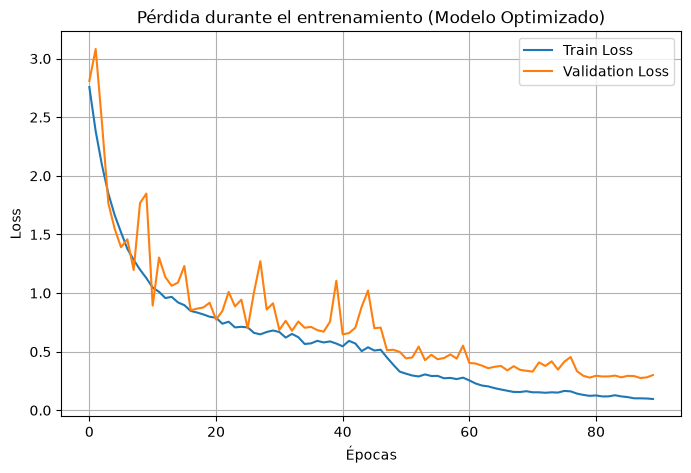

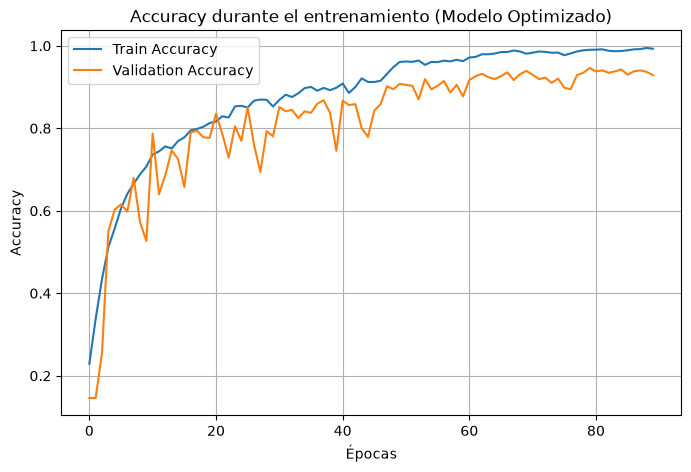

In [191]:
import matplotlib.pyplot as plt

# =========================
# LOSS
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['loss'], label='Train Loss')
plt.plot(history_opt.history['val_loss'], label='Validation Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# =========================
# ACCURACY
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['accuracy'], label='Train Accuracy')
plt.plot(history_opt.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [192]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo_opt.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo_opt.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step
===== TRAIN =====
Accuracy: 0.9997079439252337
F1-score: 0.9997079449426438

===== TEST =====
Accuracy: 0.9317757009345794
F1-score: 0.9320307184859833


aqui sacar conclusiones

In [193]:
# GUARDAR EL MODELO
modelo_opt.save("modelo_cars.keras")

# GUARDAR EL LABEL ENCODER ya que el modelo solo guarda los pesos, no la información de las clases, 
# por lo que es necesario guardar el label encoder para poder interpretar las predicciones del modelo posteriormente.
import pickle

with open("labelencoder.pkl", "wb") as f:
    pickle.dump(labelencoder, f)

# Despliegue

Cargando modelo y label encoder...
Se encontraron 802 imágenes. Procesando...

===== RESUMEN =====
Total: 802 | Aciertos: 758 | Errores: 44
Accuracy: 0.9451

Errores por clase real:
  Convertible: 3/174 errores (1.7%)
  Coupe: 10/79 errores (12.7%)
  Hatchback: 11/99 errores (11.1%)
  Pick-Up: 2/110 errores (1.8%)
  SUV: 10/125 errores (8.0%)
  Sedan: 7/109 errores (6.4%)
  VAN: 1/106 errores (0.9%)

Mostrando 44 de 44 imágenes mal clasificadas...
[Convertible] d8149822-66b6-11eb-b835-8c164571e025_jpg.rf.3c1bc58ef3da8aeefac898f7fc382d94.jpg → Predicción: Coupe (confianza 0.99)


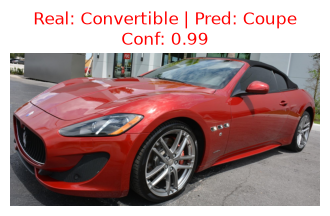

[Convertible] d8149837-66b6-11eb-b9e3-8c164571e025_jpg.rf.b29119e561c8c0b389091f0b12600e2d.jpg → Predicción: Coupe (confianza 1.00)


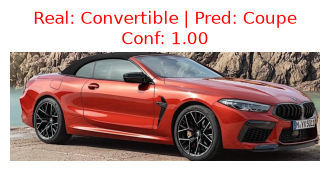

[Convertible] d814bf39-66b6-11eb-a4cb-8c164571e025_jpg.rf.d5ab471ffe435e78c827c476a1438d1f.jpg → Predicción: Coupe (confianza 0.96)


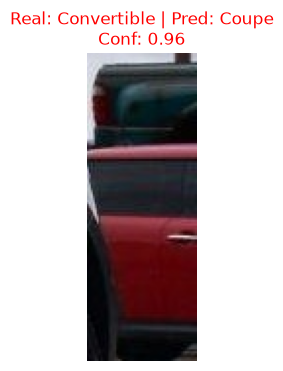

[Coupe] 00787_Infiniti-G-Coupe-IPL-2012_jpg.rf.e79fd1a3e1b7c52451090412ae574615.jpg → Predicción: Sedan (confianza 1.00)


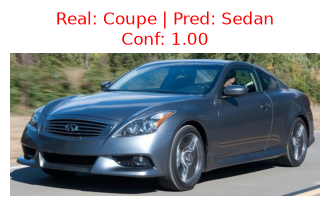

[Coupe] 02899_Audi-A5-Coupe-2012_jpg.rf.2b195e5290b2233f4544f13bc2581ac1.jpg → Predicción: Sedan (confianza 0.97)


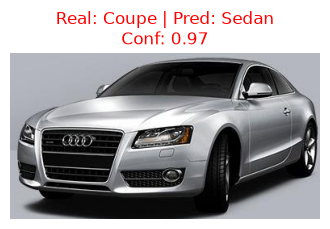

[Coupe] 03226_Audi-S5-Coupe-2012_jpg.rf.408ad8a6cf50fb9610fbde03b0b20ae4.jpg → Predicción: Sedan (confianza 0.79)


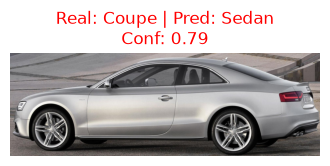

[Coupe] 04510_Aston-Martin-V8-Vantage-Coupe-2012_jpg.rf.9b6422eac00afa2c67b43a6345a6feef.jpg → Predicción: Convertible (confianza 1.00)


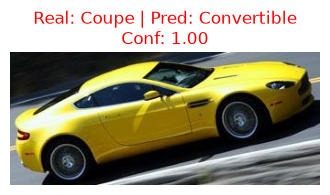

[Coupe] 06493_Honda-Accord-Coupe-2012_jpg.rf.7c2a8129792848cd89245a4e62fd4555.jpg → Predicción: Convertible (confianza 0.56)


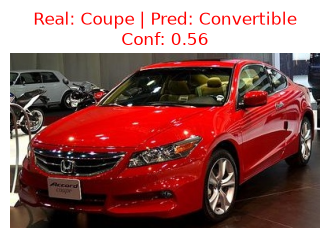

[Coupe] 0ab48d64-66b3-11eb-9141-8c164571e025_jpg.rf.8a42cb30b3b4a2f7b9e13fc793780f46.jpg → Predicción: SUV (confianza 0.96)


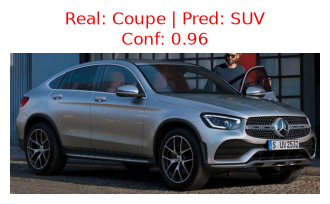

[Coupe] 173_jpg.rf.3f6d26bc2b3a933abfd57a0833704218.jpg → Predicción: Convertible (confianza 1.00)


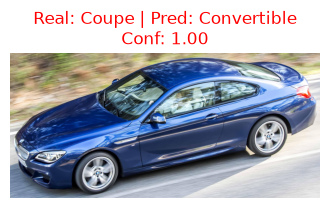

[Coupe] 286_jpg.rf.33c327ed7791e0a93d044b2eca942dc6.jpg → Predicción: Sedan (confianza 0.64)


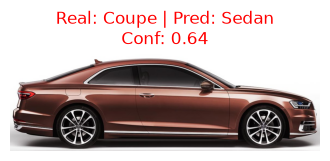

[Coupe] 77_jpg.rf.aee00019f0daef9fc545e1eae5bd81fa.jpg → Predicción: Sedan (confianza 0.94)


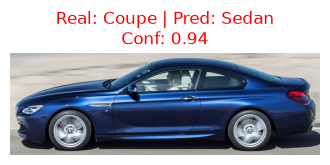

[Coupe] 80_jpg.rf.417fa09c95f9c12d09fee4cb6db4246c.jpg → Predicción: Sedan (confianza 0.66)


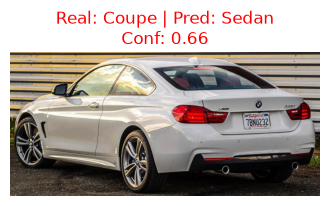

[Hatchback] 03642_Nissan-Juke-Hatchback-2012_jpg.rf.b3bce2dc909301f4d02bbe20155fe812.jpg → Predicción: Convertible (confianza 0.76)


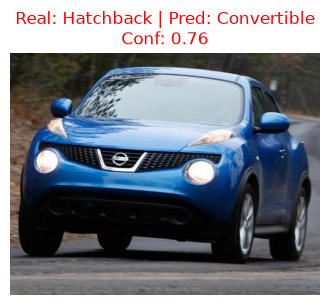

[Hatchback] 03922_Volkswagen-Golf-Hatchback-2012_jpg.rf.2e9ee3a8c1872cf6c360de7f7fa05cb9.jpg → Predicción: Sedan (confianza 0.84)


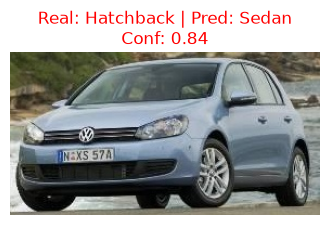

[Hatchback] 04004_Volkswagen-Golf-Hatchback-2012_jpg.rf.9c6c1c7ae0e4430a3b08657082f6c264.jpg → Predicción: SUV (confianza 0.68)


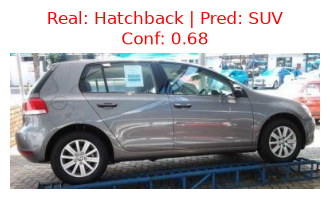

[Hatchback] 05939_Nissan-Juke-Hatchback-2012_jpg.rf.161fa5292b7c91bd3e90ca466672e382.jpg → Predicción: SUV (confianza 0.99)


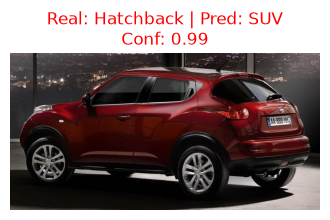

[Hatchback] 13_jpg.rf.af4b136c5e16ad9b57666f501e55bd06.jpg → Predicción: Sedan (confianza 0.99)


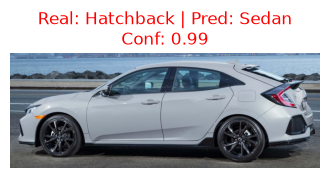

[Hatchback] 172_jpg.rf.c4edebe7300cbe7b5a0a26870be52d69.jpg → Predicción: Sedan (confianza 0.93)


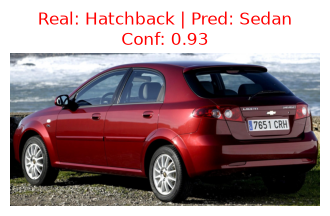

[Hatchback] d581b428-66ac-11eb-a20b-8c164571e025_jpg.rf.514cf7a98b71b84791a18bdfa353bb24.jpg → Predicción: Coupe (confianza 0.30)


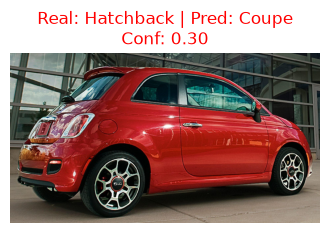

[Hatchback] d581b473-66ac-11eb-bb25-8c164571e025_jpg.rf.6cba7aece68d508854a9e09a88f236b8.jpg → Predicción: Sedan (confianza 0.97)


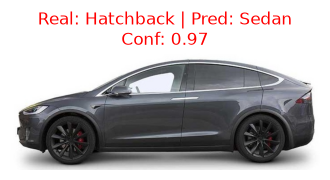

[Hatchback] d5824f75-66ac-11eb-9bb6-8c164571e025_jpg.rf.dca5310387c3f0329770eaa09ca48601.jpg → Predicción: Sedan (confianza 0.70)


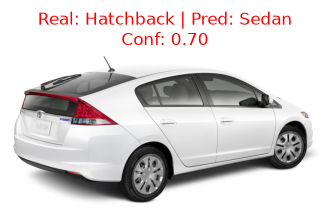

[Hatchback] d5824f90-66ac-11eb-818a-8c164571e025_jpg.rf.98b56f3dfc94f96462c142787d5c3ddd.jpg → Predicción: Sedan (confianza 0.78)


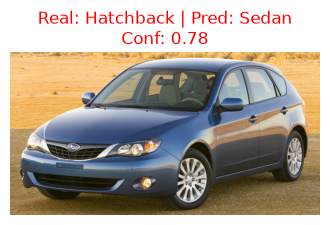

[Hatchback] d586227c-66ac-11eb-b36c-8c164571e025_jpg.rf.66f10d209c8b75a3e61fe0887fdb5087.jpg → Predicción: Sedan (confianza 0.92)


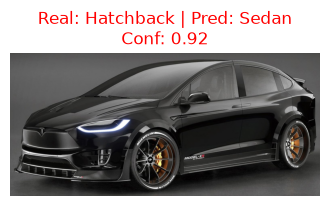

[Pick-Up] 02622_Dodge-Dakota-Crew-Cab-2010_jpg.rf.e71cef442dc126250c3ae4e2e24802e3.jpg → Predicción: Convertible (confianza 0.75)


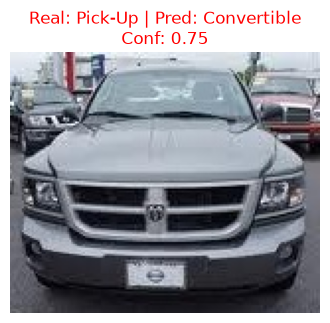

[Pick-Up] Image_66_jpg.rf.5e321eb912afd483a9c465dc6fb45d8c.jpg → Predicción: SUV (confianza 0.89)


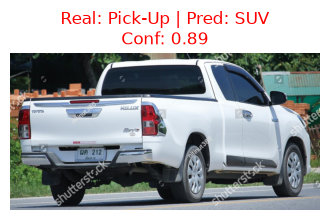

[Sedan] 00793_Audi-S4-Sedan-2007_jpg.rf.51cef7d5c5b02b4fb3f6b58e0b612dae.jpg → Predicción: Coupe (confianza 0.92)


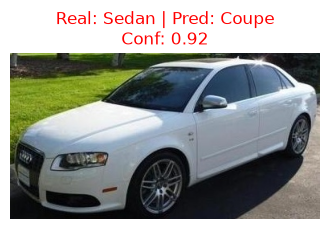

[Sedan] 03855_Audi-S4-Sedan-2007_jpg.rf.6c85dc03a752a0b23bdf227bbcb2e3be.jpg → Predicción: SUV (confianza 0.68)


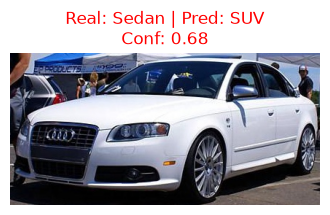

[Sedan] 392_jpg.rf.10c39b1a1164dc3fbaa8a164f16756f0.jpg → Predicción: Coupe (confianza 1.00)


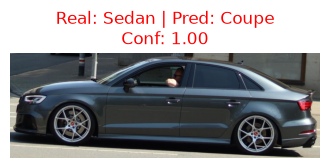

[Sedan] 44_jpg.rf.23b9e70b373e3ef5baf027fa4f0cfdc3.jpg → Predicción: Coupe (confianza 0.91)


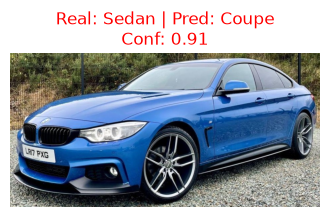

[Sedan] 466_jpg.rf.8d8a381b018b0b99d6acfb500da704fa.jpg → Predicción: Coupe (confianza 0.99)


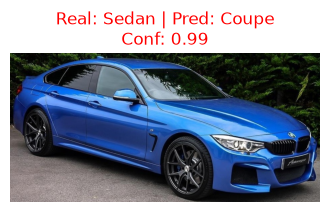

[Sedan] 867a1fce-66b6-11eb-bc11-8c164571e025_jpg.rf.2659c531f5bc07dee9eb873df99d233a.jpg → Predicción: Coupe (confianza 0.57)


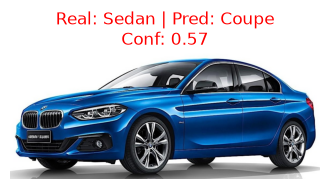

[Sedan] 91_jpg.rf.7b5e54bfbd87f407a8603b648a97cc33.jpg → Predicción: Coupe (confianza 1.00)


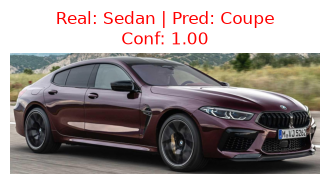

[SUV] 00843_Mazda-Tribute-SUV-2011_jpg.rf.7641d341e63328bfdb10878952bcea52.jpg → Predicción: Pick-Up (confianza 0.97)


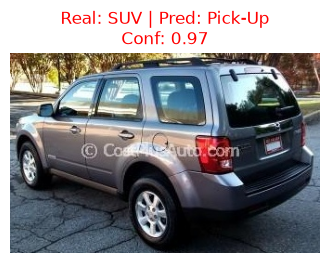

[SUV] 01050_Hyundai-Tucson-SUV-2012_jpg.rf.efc8c378a65a71b17cc75d405d3342f8.jpg → Predicción: Hatchback (confianza 0.89)


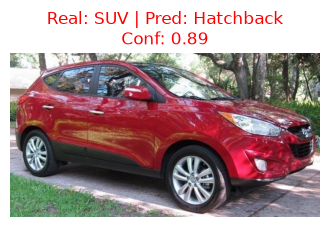

[SUV] 01279_Hyundai-Santa-Fe-SUV-2012_jpg.rf.024ad1a9945e55bb4e80df3779af24d2.jpg → Predicción: Pick-Up (confianza 0.93)


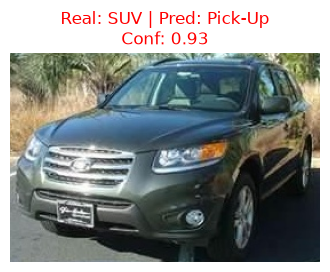

[SUV] 03126_Infiniti-QX56-SUV-2011_jpg.rf.0256dfebc0435683b68892b72c536f47.jpg → Predicción: Hatchback (confianza 0.83)


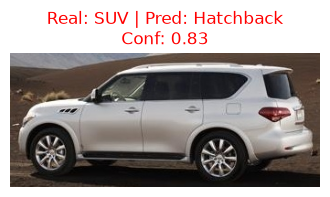

[SUV] 03837_Dodge-Journey-SUV-2012_jpg.rf.7524ece4819b9b98e7185a10749bbf1b.jpg → Predicción: Coupe (confianza 0.88)


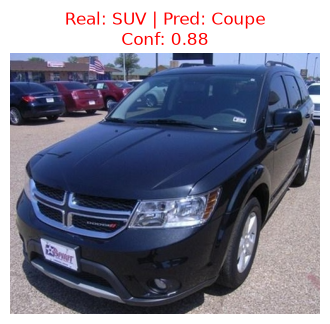

[SUV] 07997_Infiniti-QX56-SUV-2011_jpg.rf.9075edbd8d5a026ba1572b85fe286bd2.jpg → Predicción: Hatchback (confianza 0.62)


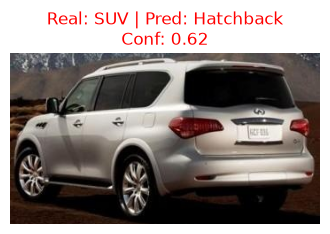

[SUV] 111_jpg.rf.82fe73ad502cca4909af19ebddd66e93.jpg → Predicción: Sedan (confianza 0.96)


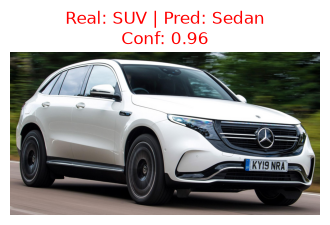

[SUV] 161_jpg.rf.af01205d2e47cdef215ef24b4fe6fc21.jpg → Predicción: Hatchback (confianza 0.64)


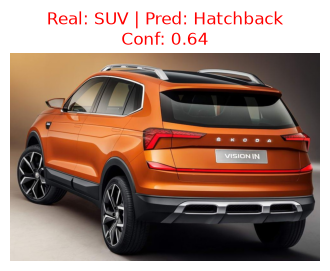

[SUV] 349_jpg.rf.401a8d6b4d2e5921f85e4c0fb64807ac.jpg → Predicción: Hatchback (confianza 0.91)


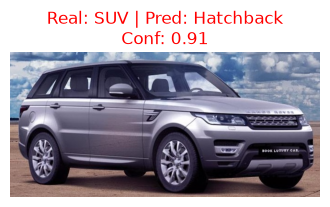

[SUV] Image_86_jpg.rf.080f77c37cb03a003c35ae2dd8257523.jpg → Predicción: Sedan (confianza 0.83)


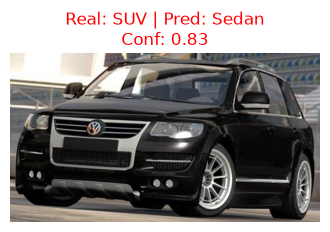

[VAN] 121_jpg.rf.66f2627045929e12e101e5b3fb59d05f.jpg → Predicción: Hatchback (confianza 1.00)


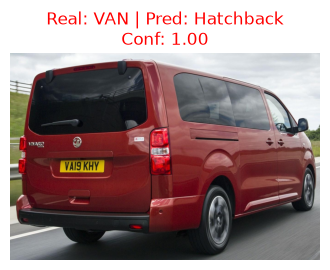

In [194]:
import os
import numpy as np
from PIL import Image
import pickle
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

# 1. Cargar modelo y label encoder
print("Cargando modelo y label encoder...")
modelo = load_model("modelo_cars.keras")

with open("labelencoder.pkl", "rb") as f:
    labelencoder = pickle.load(f)

# 2. Ruta de prueba
ruta_nuevos = r"Cars_Body_Type/test"
img_size = (150, 150)
EXTENSIONES = ('.jpg', '.jpeg', '.png')

# 3. Función: predice todo, pero solo muestra las incorrectas
def predecir_y_mostrar_errores(ruta_raiz, modelo, labelencoder, img_size=img_size, max_mostrar=None):
    resultados = []   # (archivo, clase_real, clase_pred, correcta)
    errores = []      # (ruta, clase_real, clase_pred)

    if not os.path.exists(ruta_raiz):
        print(f"Error: La ruta '{ruta_raiz}' no existe.")
        return resultados

    # Recolectar rutas de imágenes
    rutas = []
    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(EXTENSIONES):
                rutas.append(os.path.join(root, archivo))

    if not rutas:
        print(f"No se encontraron imágenes válidas en '{ruta_raiz}'.")
        return resultados

    print(f"Se encontraron {len(rutas)} imágenes. Procesando...")

    for ruta in rutas:
        clase_real = os.path.basename(os.path.dirname(ruta))

        # Cargar y preprocesar (convert('RGB') evita fallos con PNG/escala de grises)
        img = Image.open(ruta).convert("RGB")
        img_array = np.array(img.resize(img_size)) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        # Predicción
        pred = modelo.predict(img_array, verbose=0)
        clase_pred = labelencoder.inverse_transform(np.argmax(pred, axis=1))[0]

        correcta = str(clase_pred) == str(clase_real)
        resultados.append((os.path.basename(ruta), clase_real, clase_pred, correcta))

        if not correcta:
            errores.append((ruta, clase_real, clase_pred, float(np.max(pred))))

    # 4. Resumen general
    total = len(resultados)
    aciertos = sum(r[3] for r in resultados)
    print(f"\n===== RESUMEN =====")
    print(f"Total: {total} | Aciertos: {aciertos} | Errores: {len(errores)}")
    print(f"Accuracy: {aciertos / total:.4f}")

    # Errores por clase real
    print("\nErrores por clase real:")
    clases = sorted({r[1] for r in resultados})
    for c in clases:
        tot_c = sum(1 for r in resultados if r[1] == c)
        err_c = sum(1 for r in resultados if r[1] == c and not r[3])
        print(f"  {c}: {err_c}/{tot_c} errores ({err_c / tot_c:.1%})")

    # 5. Mostrar solo las mal clasificadas
    if not errores:
        print("\nNo hubo errores de clasificación.")
        return resultados

    a_mostrar = errores if max_mostrar is None else errores[:max_mostrar]
    print(f"\nMostrando {len(a_mostrar)} de {len(errores)} imágenes mal clasificadas...")

    for ruta, clase_real, clase_pred, confianza in a_mostrar:
        print(f"[{clase_real}] {os.path.basename(ruta)} → Predicción: {clase_pred} (confianza {confianza:.2f})")
        plt.figure(figsize=(4, 4))
        plt.imshow(Image.open(ruta).convert("RGB"))
        plt.title(f"Real: {clase_real} | Pred: {clase_pred}\nConf: {confianza:.2f}", color="red")
        plt.axis("off")
        plt.show()

    return resultados

# Ejecutar
resultados = predecir_y_mostrar_errores(ruta_nuevos, modelo, labelencoder)

Mal clasificadas: 44 de 802 (5.5%)
Bien clasificadas: 758 de 802 (94.5%)
             total  aciertos  errores  % error
real                                          
Coupe           79        69       10     12.7
Hatchback       99        88       11     11.1
SUV            125       115       10      8.0
Sedan          109       102        7      6.4
Pick-Up        110       108        2      1.8
Convertible    174       171        3      1.7
VAN            106       105        1      0.9

Confusiones más frecuentes:
real         pred       
Hatchback    Sedan          7
Sedan        Coupe          6
Coupe        Sedan          6
SUV          Hatchback      5
Convertible  Coupe          3
Coupe        Convertible    3
SUV          Sedan          2
             Pick-Up        2
Hatchback    SUV            2
Pick-Up      Convertible    1
Name: cantidad, dtype: int64


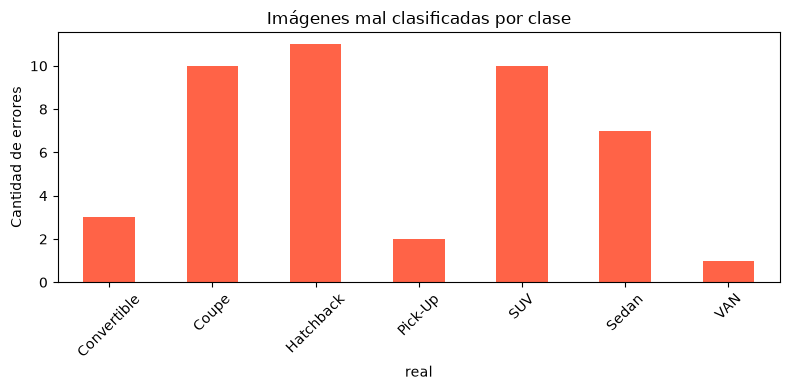

In [195]:
import pandas as pd

df = pd.DataFrame(resultados, columns=["archivo", "real", "pred", "correcta"])

total = len(df)
errores = (~df["correcta"]).sum()
print(f"Mal clasificadas: {errores} de {total} ({errores/total:.1%})")
print(f"Bien clasificadas: {total - errores} de {total} ({(total-errores)/total:.1%})")

# Errores por clase real
resumen = df.groupby("real")["correcta"].agg(
    total="count",
    aciertos="sum"
)
resumen["errores"] = resumen["total"] - resumen["aciertos"]
resumen["% error"] = (resumen["errores"] / resumen["total"] * 100).round(1)
print(resumen.sort_values("% error", ascending=False))

# Qué clases se confunden entre sí (real -> predicha)
confusiones = (
    df[~df["correcta"]]
    .groupby(["real", "pred"])
    .size()
    .sort_values(ascending=False)
    .rename("cantidad")
)
print("\nConfusiones más frecuentes:")
print(confusiones.head(10))

# Gráfico de errores por clase
resumen["errores"].plot(kind="bar", color="tomato", figsize=(8, 4))
plt.title("Imágenes mal clasificadas por clase")
plt.ylabel("Cantidad de errores")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [196]:
# import os
# import numpy as np
# from PIL import Image
# import pickle
# from tensorflow.keras.models import load_model
# import matplotlib.pyplot as plt

# # 1. Cargar modelo y label encoder
# print("Cargando modelo y label encoder...")
# modelo = load_model("modelo_cars.keras")

# with open("labelencoder.pkl", "rb") as f:
#     labelencoder = pickle.load(f)

# # 2. Definir ruta de prueba
# ruta_nuevos = r"Cars_Body_Type/test"
# img_size = (150, 150)

# # 3. Función actualizada para buscar imágenes dentro de subcarpetas
# def predecir_y_mostrar_carpetas(ruta_raiz, modelo, labelencoder, img_size=img_size):
#     resultados = []
    
#     if not os.path.exists(ruta_raiz):
#         print(f"Error: La ruta '{ruta_raiz}' no existe.")
#         return resultados

#     # Usamos os.walk para recorrer la carpeta principal y todas sus subcarpetas
#     total_imagenes = 0
#     for root, dirs, files in os.walk(ruta_raiz):
#         for archivo in files:
#             if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
#                 total_imagenes += 1

#     if total_imagenes == 0:
#         print(f"No se encontraron imágenes válidas en '{ruta_raiz}' ni en sus subcarpetas.")
#         return resultados

#     print(f"Se encontraron {total_imagenes} imágenes. Procesando...")

#     for root, dirs, files in os.walk(ruta_raiz):
#         for archivo in files:
#             if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
#                 ruta = os.path.join(root, archivo)
#                 # Opcional: obtener la clase real basada en el nombre de la subcarpeta
#                 clase_real = os.path.basename(root)

#                 # Cargar y preprocesar la imagen
#                 img = Image.open(ruta)
#                 img_resized = img.resize(img_size)
                
#                 img_array = np.array(img_resized) / 255.0
#                 img_array = np.expand_dims(img_array, axis=0)

#                 # Predicción
#                 pred = modelo.predict(img_array, verbose=0)
#                 clase_pred = np.argmax(pred, axis=1)

#                 # Convertir a etiqueta original
#                 etiqueta = labelencoder.inverse_transform(clase_pred)
                
#                 resultados.append((archivo, etiqueta[0]))

#                 # Imprimir resultado en consola (mostrando la carpeta/clase real y la predicha)
#                 print(f"[{clase_real}] {archivo} → Predicción: {etiqueta[0]}")

#                 # Mostrar imagen con matplotlib
#                 plt.figure(figsize=(4, 4))
#                 plt.imshow(img)
#                 plt.title(f"Real: {clase_real} | Pred: {etiqueta[0]}")
#                 plt.axis("off")
#                 plt.show()

#     return resultados

# # Ejecutar el proceso actualizado
# resultados = predecir_y_mostrar_carpetas(ruta_nuevos, modelo, labelencoder)